In [1]:

import pandas as pd
from sklearn.model_selection import train_test_split

# Load cleaned dataset
df = pd.read_csv("cleaned_city_day.csv")

# Select input features
features = [
    "PM2.5",
    "PM10",
    "NO2",
    "CO",
    "O3",
    "SO2"
]

# Input data
X = df[features]

# Target data
y = df["AQI"]

# Split dataset (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Display results
print("Original Dataset:", df.shape)
print("Training Input:", X_train.shape)
print("Testing Input:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Original Dataset: (16010, 7)
Training Input: (12808, 6)
Testing Input: (3202, 6)
Training Target: (12808,)
Testing Target: (3202,)


In [2]:

from sklearn.ensemble import RandomForestRegressor
import joblib

# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest Model Training Completed!")


Random Forest Model Training Completed!


In [3]:

# Predict AQI using testing data
y_pred = rf_model.predict(X_test)

# Display first 10 predictions
print("Actual AQI:", y_test.head(10).values)
print("Predicted AQI:", y_pred[:10])


Actual AQI: [ 86.  95. 532. 386.  69. 147. 103. 168. 347.  48.]
Predicted AQI: [ 80.75  83.56 520.12 582.74  65.12 164.33  94.   138.3  313.27  54.33]


In [4]:

joblib.dump(rf_model, "aqi_random_forest.pkl")

print("Model saved successfully!")


Model saved successfully!


### Model Evaluation

In [5]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

# Display results
print("MODEL EVALUATION RESULTS")
print("------------------------")
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))


MODEL EVALUATION RESULTS
------------------------
MAE: 16.54
MSE: 827.12
RMSE: 28.76
R2 Score: 0.924


# Data Visualization
### Actual vs Predicted AQI

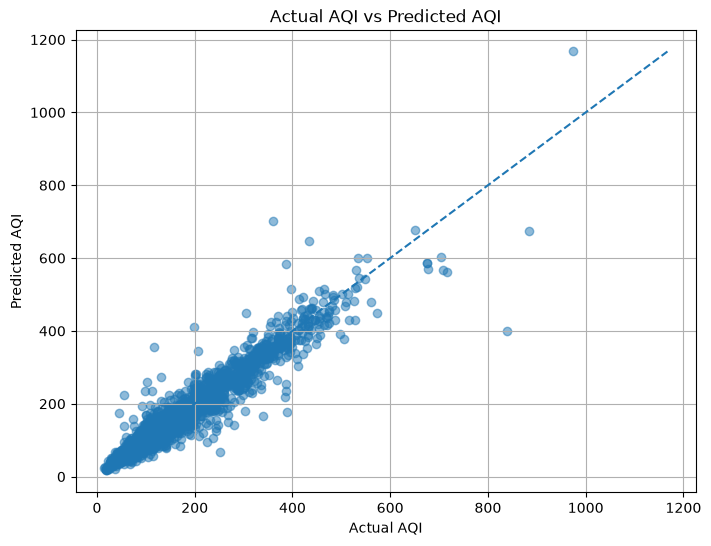

In [6]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.5
)

# Perfect prediction reference line
minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")
plt.title("Actual AQI vs Predicted AQI")
plt.grid(True)

plt.show()


### Feature Importance

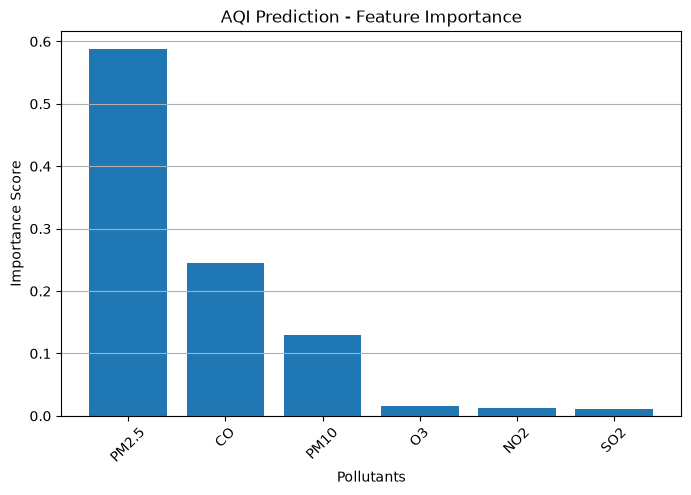

  Feature  Importance
0   PM2.5    0.587553
3      CO    0.244456
1    PM10    0.129254
4      O3    0.015936
2     NO2    0.012167
5     SO2    0.010633


In [7]:

import pandas as pd
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(8, 5))

plt.bar(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Pollutants")
plt.ylabel("Importance Score")
plt.title("AQI Prediction - Feature Importance")
plt.xticks(rotation=45)
plt.grid(axis="y")

plt.show()

print(importance)


### Prediction Error Distribution

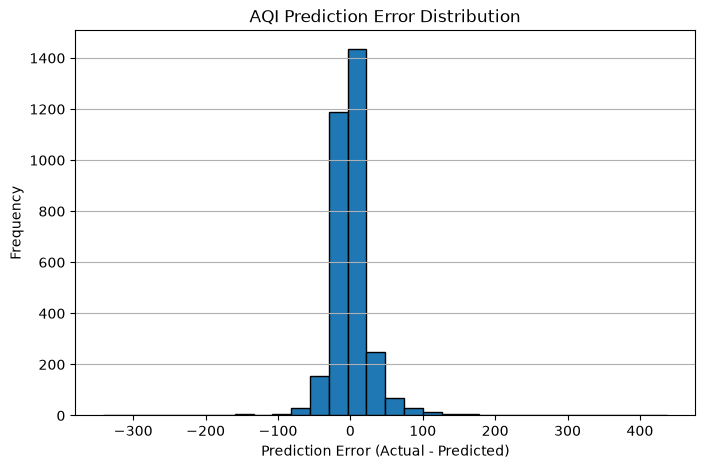

In [8]:

import matplotlib.pyplot as plt

errors = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.hist(
    errors,
    bins=30,
    edgecolor="black"
)

plt.xlabel("Prediction Error (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("AQI Prediction Error Distribution")
plt.grid(axis="y")

plt.show()
